# Who Survived the Titanic?

**Minor Project – 2 | Data Analysis and Visualization using Python**  
Praveen Yadav, MCA, Lovely Professional University

For this project, I am using the Titanic dataset from Kaggle. I wanted to find out whether a passenger's gender, age, ticket class or family size had anything to do with their chance of surviving.

I'll first have a look at the data, deal with the missing values, and then use a few charts to make the patterns easier to understand.

## 1. Importing the libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 2. Loading the data

I'm using Kaggle's *Titanic: Machine Learning from Disaster* dataset.
My CSV file in a folder called `data`, so the path below points to that file.

In [2]:
df = pd.read_csv("data/titanic.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### size, column types and basic statistics

In [3]:
print("Rows, Columns:", df.shape)
print()
df.info()

Rows, Columns: (891, 12)

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
df.describe().round(2)

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,714.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,14.53,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,20.12,0.00,0.00,7.91
50%,446.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,38.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


The dataset has **891 passengers and 12 columns**.

## 3. Cleaning the data

In [3]:
# Checking which columns have missing data
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Age         177
Cabin       687
Embarked      2
dtype: int64

I found missing values in three columns: `Age` (177), `Embarked` (2) and `Cabin` (687).

Here's how I handled them:

- **Age:** I filled the gaps with the median age.
- **Embarked:** Only two values are missing, so I filled the most common property is mode.
- **Cabin:** Almost empty, so I removed this column for this analysis.

In [4]:
# I filled the gaps with the median age.
df["Age"] = df["Age"].fillna(df["Age"].median())

# Only two values are missing, so I filled the most common property is mode.
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Almost empty, so I removed this column for this analysis.
df = df.drop(columns=["Cabin"])

print("Missing values remaining:", df.isnull().sum().sum())

Missing values remaining: 0


### Adding a couple of columns

The original data has separate columns for siblings/spouses and parents/children. I combined them into one `FamilySize` column, including the passenger.

I also made an `AgeGroup` column. This should make it a little easier to compare survival rates across age ranges.

In [7]:
# Count the passenger as well as the relatives travelling with them.
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

# Grouping ages makes it easier to compare survival between age ranges.
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 12, 18, 40, 60, 100],
    labels=["Child", "Teen", "Adult", "Middle-aged", "Senior"]
)

df[["Age", "AgeGroup", "SibSp", "Parch", "FamilySize"]].head()

,Age,AgeGroup,SibSp,Parch,FamilySize
0,22.0,Adult,1,0,2
1,38.0,Adult,1,0,2
2,26.0,Adult,0,0,1
3,35.0,Adult,1,0,2
4,35.0,Adult,0,0,1


## 4. Exploring the numbers

Before making the charts, I checked the survival rates directly. The `Survived` column uses 1 for a passenger who survived and 0 for one who did not, so taking its average gives the survival rate.

In [8]:
overall_rate = df["Survived"].mean() * 100
print("Overall survival rate: {:.1f}%".format(overall_rate))

print("\nSurvival rate by gender (%):")
gender_rates = df.groupby("Sex")["Survived"].mean() * 100
print(gender_rates.round(1))

print("\nSurvival rate by passenger class (%):")
class_rates = df.groupby("Pclass")["Survived"].mean() * 100
print(class_rates.round(1))

print("\nSurvival rate by age group (%):")
age_rates = df.groupby("AgeGroup", observed=True)["Survived"].mean() * 100
print(age_rates.round(1))

Overall survival rate: 38.4%

By gender (%):
Sex
female    74.2
male      18.9
Name: Survived, dtype: float64

By class (%):
Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64

By age group (%):
AgeGroup
Child          58.0
Teen           42.9
Adult          36.0
Middle-aged    39.1
Senior         22.7
Name: Survived, dtype: float64


The overall survival rate is **38.4%**. The rates are quite different when I compare passengers by gender and class, so the charts should make those differences clearer.

## 5. Visualizations

### 5.1 Overall survival (pie chart)

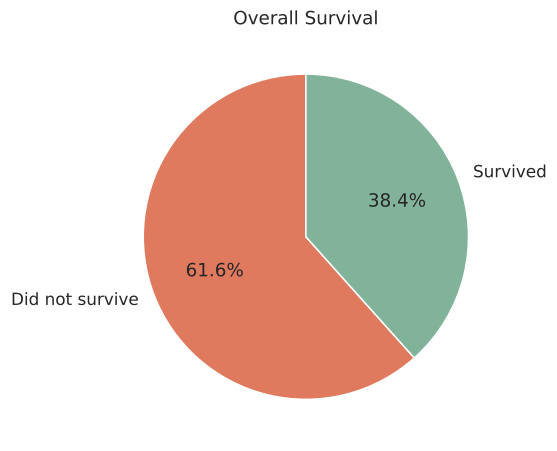

In [9]:
df["Survived"].map({0: "Did not survive", 1: "Survived"}).value_counts().plot(
    kind="pie", autopct="%1.1f%%", colors=["#e07a5f", "#81b29a"], startangle=90, ylabel="")
plt.title("Overall Survival")
plt.show()

Fewer than 4 out of 10 passengers made it.

### 5.2 Gender (bar chart)

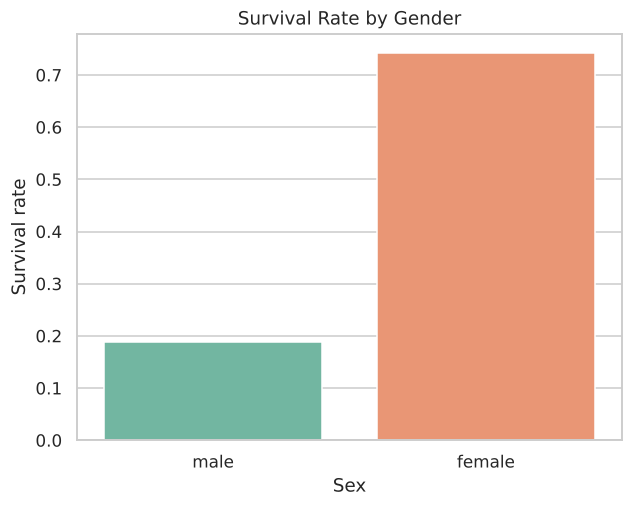

In [10]:
sns.barplot(data=df, x="Sex", y="Survived", hue="Sex", palette="Set2", errorbar=None, legend=False)
plt.title("Survival Rate by Gender")
plt.ylabel("Survival rate")
plt.show()

**What I noticed:** Around 74% of women survived, compared with about 19% of men.

### 5.3 Passenger class (bar chart and box plot)

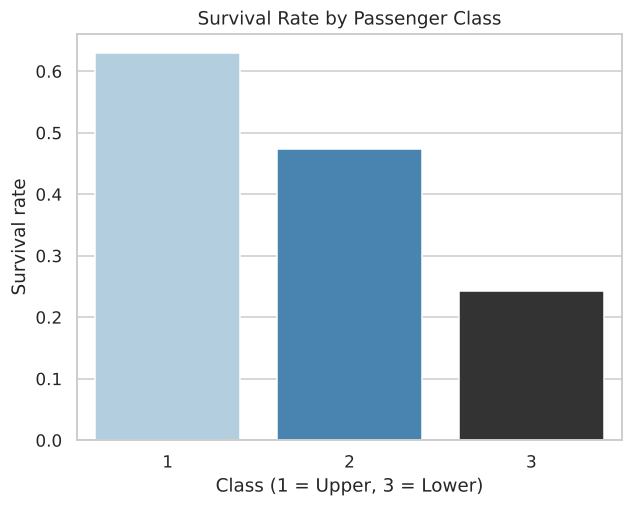

In [11]:
sns.barplot(data=df, x="Pclass", y="Survived", hue="Pclass", palette="Blues_d", errorbar=None, legend=False)
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Class (1 = Upper, 3 = Lower)")
plt.ylabel("Survival rate")
plt.show()

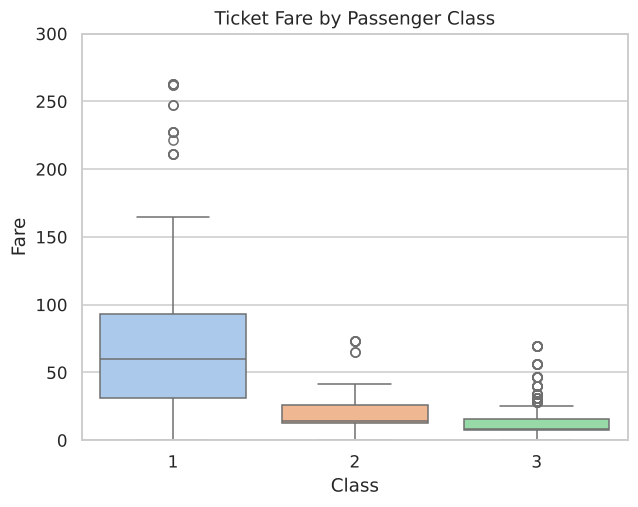

In [12]:
sns.boxplot(data=df, x="Pclass", y="Fare", hue="Pclass", palette="pastel", legend=False)
plt.ylim(0, 300)   # cut at 300 so a few extreme fares don't squash the chart
plt.title("Ticket Fare by Passenger Class")
plt.xlabel("Class")
plt.show()

**What I noticed:** The survival rate was about 63% in first class, 47% in second class and 24% in third class.

### 5.4 Age (histogram and bar chart)

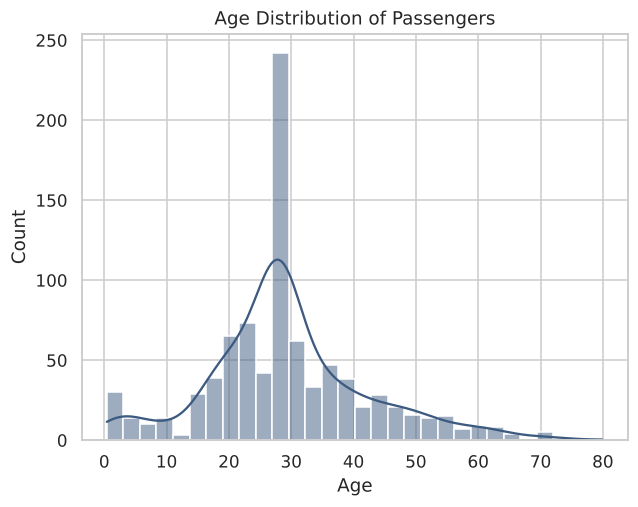

In [13]:
sns.histplot(df["Age"], bins=30, kde=True, color="#3d5a80")
plt.title("Age Distribution of Passengers")
plt.show()

Most passengers were between 20 and 40 years old. One thing worth pointing out is the spike around age 28 because I filled missing ages using the median, which is around 28.

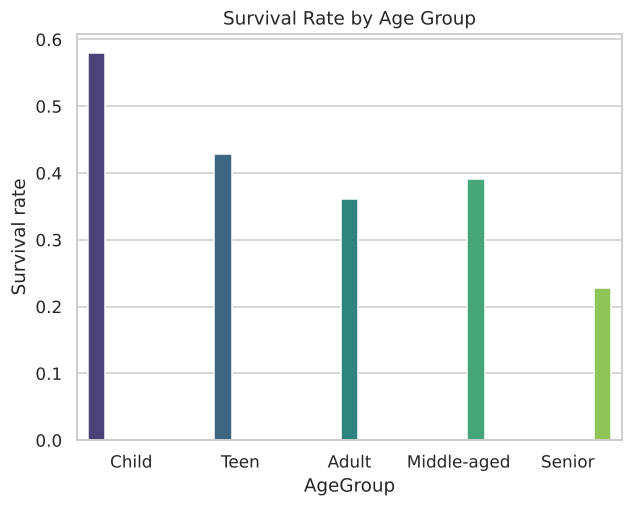

In [14]:
sns.barplot(data=df, x="AgeGroup", y="Survived", hue="AgeGroup", palette="viridis", errorbar=None, legend=False)
plt.title("Survival Rate by Age Group")
plt.ylabel("Survival rate")
plt.show()

**What I noticed:** Children had the highest survival rate (around 58%), while the senior group had the lowest (around 23%).

### 5.5 Family size (line chart)

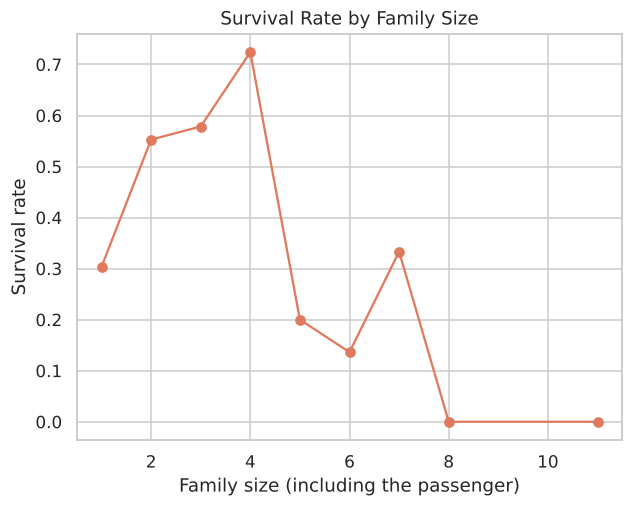

In [15]:
df.groupby("FamilySize")["Survived"].mean().plot(kind="line", marker="o", color="#e07a5f")
plt.title("Survival Rate by Family Size")
plt.xlabel("Family size (including the passenger)")
plt.ylabel("Survival rate")
plt.show()

**What I noticed:** Passengers travelling alone had a survival rate of around 30%. Smaller families, especially groups of 2 to 4, generally did better. Larger families had lower rates.

### 5.6 Correlation (heatmap)

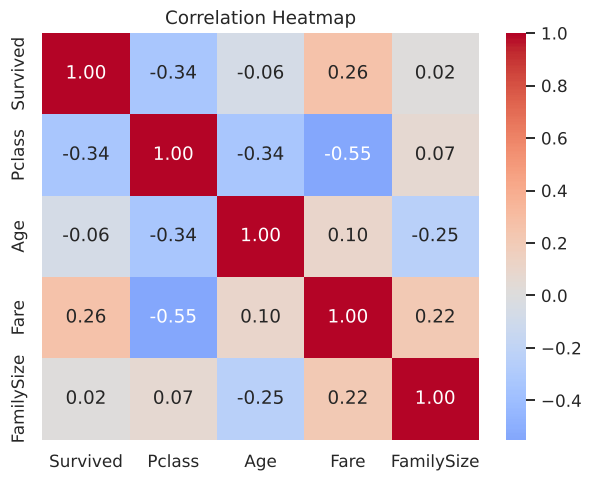

In [16]:
# Correlation between a few numeric columns used in this project
corr_columns = ["Survived", "Pclass", "Age", "Fare", "FamilySize"]
correlation = df[corr_columns].corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation Heatmap")
plt.show()

**What I noticed:** `Pclass` has a negative correlation with `Survived` (-0.34). Since 1 is the highest class and 3 is the lowest, this means survival tended to be higher in the better classes. `Fare` has a positive correlation with survival (0.26). Fare and passenger class are also related to each other (-0.55).

These values show relationships, not proof that one factor directly caused another.

### 5.7 Gender and class together

In [17]:
(df.pivot_table(values="Survived", index="Pclass", columns="Sex", aggfunc="mean") * 100).round(1)

Sex,female,male
Pclass,,
1,96.8,36.9
2,92.1,15.7
3,50.0,13.5


This comparison brings gender and class together. In this dataset, first-class women had a survival rate of about 97%, while third-class men were at about 14%.

## 6. Main findings

A few patterns stood out to me from this analysis:

- Overall, **38.4%** of the passengers survived.
- **Women** had a much higher survival rate than men (about 74% compared with 19%).
- **First-class passengers** did better than third-class passengers (about 63% compared with 24%).
- **Children** had the highest survival rate among the age groups, while seniors had the lowest.
- Passengers in smaller families generally did better than people travelling alone or in very large families.
- Looking at gender and class together shows some of the biggest differences.

## 7. Conclusion

From this dataset, survival on the Titanic does not look evenly spread across all passengers. Gender, passenger class, age and family size were all associated with different survival rates.

Working through this project gave me practice with the main steps of a data analysis task: loading data, checking and handling missing values, creating useful columns, comparing groups and presenting the results with charts.

There are also a couple of things to keep in mind. These results show patterns, but they don't prove why those patterns happened. Also, filling missing ages with the median affects the age distribution. If I continue this project, I'd like to try a simple machine learning model and see how well it predicts survival.